<a href="https://colab.research.google.com/github/ayanbanerjee973-afk/Employee-Attrition-Retention-Analysis/blob/main/HR_EMPLOYEE_ATTRITION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# CSV data load
df = pd.read_csv('/content/hr_employee_churn_data.csv')
df.head()

,empid,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,promotion_last_5years,salary,left
0,1,0.38,0.53,2,157,3,0,0,low,1
1,2,0.80,0.86,5,262,6,0,0,medium,1
2,3,0.11,0.88,7,272,4,0,0,medium,1
3,4,0.72,0.87,5,223,5,0,0,low,1
4,5,0.37,0.52,2,159,3,0,0,low,1


In [ ]:
# Data Cleaning
print("Total row and column:",df.shape)
print("number of null data:",df.isnull().sum())
df = df.drop_duplicates().reset_index(drop=True)
print("Number of duplicate data:",df.duplicated().sum())
print("Total rows after deleting duplicates:",len(df))

df['satisfaction_level'] = df['satisfaction_level'].fillna(df['satisfaction_level'].mean())
print("number of null data:", df.isnull().sum())


Total row and column: (14999, 10)
number of null data: empid                    0
satisfaction_level       2
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
promotion_last_5years    0
salary                   0
left                     0
dtype: int64
Number of duplicate data: 0
Total rows after deleting duplicates: 14999
number of null data: empid                    0
satisfaction_level       0
last_evaluation          0
number_project           0
average_montly_hours     0
time_spend_company       0
Work_accident            0
promotion_last_5years    0
salary                   0
left                     0
dtype: int64


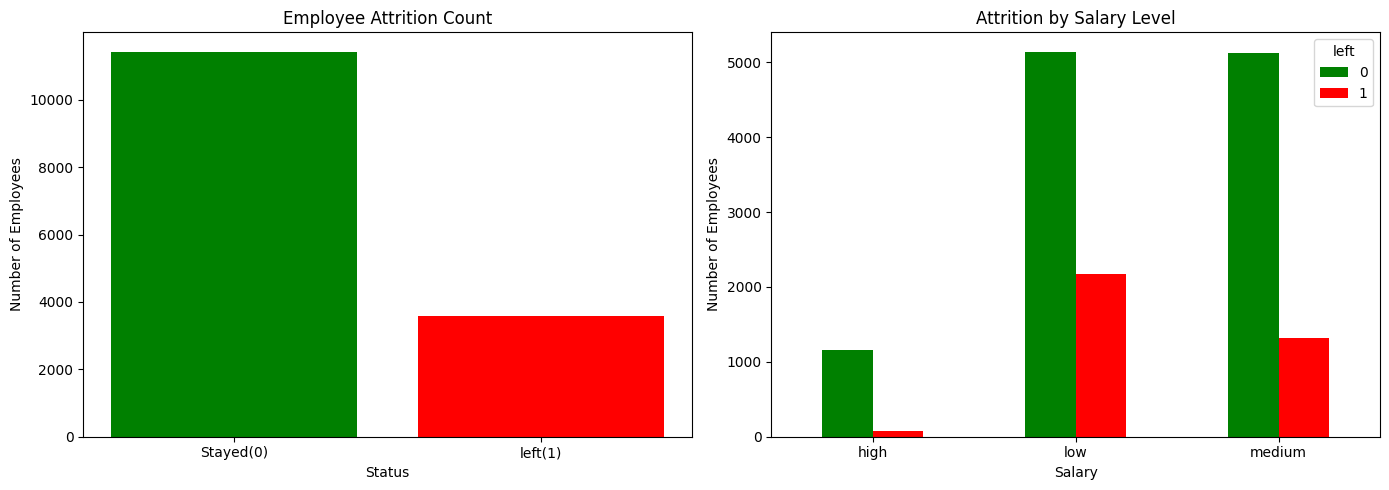

In [ ]:
# Exploratory Data Analysis
plt.figure(figsize=(14,5))

# 1.How many people left their jobs(Target analysis)
plt.subplot(1,2,1)
left_counts = df['left'].value_counts()
plt.bar(['Stayed(0)','left(1)'],left_counts.values,color=['green','red'])
plt.title('Employee Attrition Count')
plt.xlabel('Status')
plt.ylabel('Number of Employees')

# 2.Relation between salary and job turnover
plt.subplot(1,2,2)
salary_left = pd.crosstab(df['salary'],df['left'])
salary_left.plot(kind='bar',ax=plt.subplot(1,2,2),color=['green','red'])
plt.title("Attrition by Salary Level")
plt.xlabel("Salary")
plt.ylabel("Number of Employees")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [ ]:
# Feature processing

# 1.One-Hot Encoding
df_encoded = pd.get_dummies(df,columns=['salary'],drop_first = True)

# 2.seperate Time , Event and Features
time_col = 'time_spend_company'
event_col = 'left'
features = [c for c in df_encoded.columns if c not in [time_col,event_col,'empid']]

X = df_encoded[features]
E = df_encoded[event_col]
T = df_encoded[time_col]

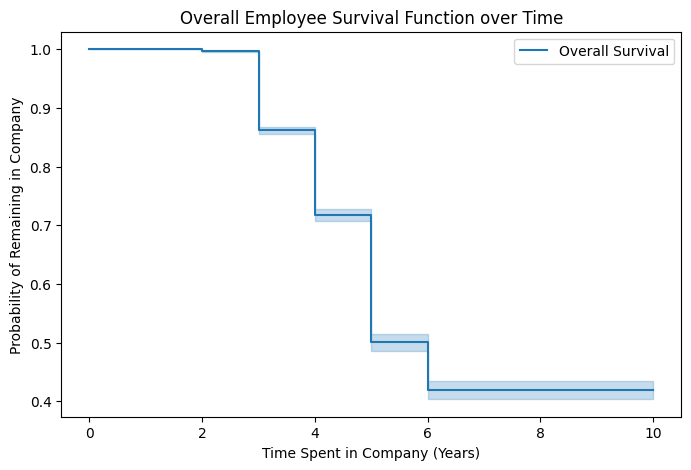

<lifelines.CoxPHFitter: fitted with 11999 total observations, 9134 right-censored observations>
             duration col = 'time_spend_company'
                event col = 'left'
      baseline estimation = breslow
   number of observations = 11999
number of events observed = 2865
   partial log-likelihood = -22975.07
         time fit was run = 2026-11-03 15:16:26 UTC

---
                       coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                              
satisfaction_level    -2.51      0.08      0.08           -2.65           -2.36                0.07                0.09
last_evaluation       -0.38      0.69      0.12           -0.61           -0.14                0.54                0.87
number_project        -0.33      0.72      0.02           -0.36           -0.30                0.70                0.74
average_montly_hours   0.00      1.00      0.00            0.00            0.00                1.00                1.00
Work_accident         -1.25      0.29      0.09           -1.42           -1.08                0.24                0.34
promotion_last_5years -1.36      0.26      0.25           -1.85           -0.87                0.16                0.42
salary_low             1.68      5.38      0.13            1.43            1.94                4.18                6.94
salary_medium          1.27      3.55      0.13            1.01            1.52                2.75                4.59

                       cmp to      z      p  -log2(p)
covariate                                            
satisfaction_level       0.00 -32.99 <0.005    790.33
last_evaluation          0.00  -3.14 <0.005      9.23
number_project           0.00 -19.70 <0.005    284.61
average_montly_hours     0.00   5.09 <0.005     21.40
Work_accident            0.00 -14.23 <0.005    150.26
promotion_last_5years    0.00  -5.42 <0.005     23.98
salary_low               0.00  12.99 <0.005    125.70
salary_medium            0.00   9.69 <0.005     71.28
---
Concordance = 0.86
Partial AIC = 45966.14
log-likelihood ratio test = 2119.23 on 8 df
-log2(p) of ll-ratio test = inf

In [ ]:
from sklearn.model_selection import train_test_split
from lifelines import KaplanMeierFitter, CoxPHFitter

# 1. Kaplan-Meier Survival Curve
kmf = KaplanMeierFitter()
kmf.fit(durations=T, event_observed=E, label='Overall Survival')

plt.figure(figsize=(8, 5))
kmf.plot_survival_function()
plt.title('Overall Employee Survival Function over Time')
plt.xlabel('Time Spent in Company (Years)')
plt.ylabel('Probability of Remaining in Company')
plt.show()

# 2. Cox Proportional Hazards Model
cph = CoxPHFitter()
# Train-Test-Split and Create Survival Dataframe
df_train,df_test=train_test_split(df_cph,test_size=0.2,random_state=42)
cph_train=CoxPHFitter()
cph_train.fit(df_train,duration_col=time_col,event_col=event_col)

# 3.Effects on Different Features(Hazard Ratios)
cph_train.print_summary()

In [ ]:
# Model evaluation
print(f"Model Concordance Index(C-Index):{cph.concordance_index_:3f}")

Model Concordance Index(C-Index):0.854928


Enter employee index:0
Employee Risk Score:0.189


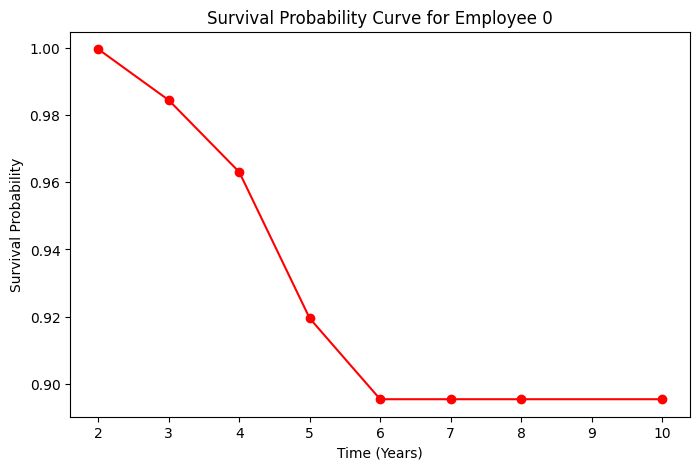

In [ ]:
# Individual Risk Score Calculator

def calculate_employee_risk(employee_data,cph_model):
  df_emp=pd.DataFrame([employee_data])
  risk_score=cph_model.predict_partial_hazard(df_emp).values[0]
  survival_curve=cph_model.predict_survival_function(df_emp)

  return risk_score,survival_curve

employee_index=int(input("Enter employee index:"))
X_sample=df_test.drop(columns=[time_col,event_col]).iloc[[employee_index]]
risk_score,survival_curve=calculate_employee_risk(X_sample.iloc[0].to_dict(),cph_train)
print(f"Employee Risk Score:{risk_score:.3f}")

# Plotting Survival Curve

plt.figure(figsize=(8,5))
plt.plot(survival_curve.index,survival_curve.iloc[:,0],marker='o',color='red')
plt.title(f"Survival Probability Curve for Employee {employee_index}")
plt.xlabel("Time (Years)")
plt.ylabel("Survival Probability")
plt.show()